# Notebook

L'expérience décrite dans le papier, ne propose pas de modèle baseline auquel comparer la nouvelle approche Online NMF. C'est l'objet de la poursuite que nous proposons. On suit 3 variables dans le temps, avec observations quotidiennes : les nouvelles contaminations confirmées, les nouveaux décès et les nouveux rétablissement du COVID-19. 

Voici plusieurs modélisations / prédicitons classiques possibles dans ce cas de figure :
- Prédicition naïve : on prédit la prochaine valeur par la dernière disponible $\hat{X}_{t+1|t} = X_t$ ;
- Prédiction avec moyenne mobile : on prédit la prochaine valeur comme moyenne des k dernières disponibles $\hat{X}_{t+1|t} = 1/k \sum_{j=0}^{k-1}{X_{t-j}}$;
- ARIMA(p, d, q) sur chaque série : un modèle par couple (variable, pays) ;
- VAR(p) sur le vecteur $X_t = (\text{confirmed}_t, \text{deaths}_t, \text{recovered}_t)^\top$.

À l'évidence, la faiblesse des 3 premiers modèles est qu'ils ne peuvent exploiter les intéractions entre les différentes variables et les différents pays. Le quatrième, quant à lui, exploite les intéractions entre les 3 variables pour un pays donné mais pas les intéractions entre pays. L'apprentissage d'un dictionnaire est le seul qui joue sur les deux types d'intéractions.

Nous comparerons les RMSE (par rapport aux valeurs effectives) des prédicitions obtenues par ces différentes approches avec celles des prédictions obtenues par le papier avec Online NMF.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error
import numpy as numpy

## Lecture et pré-traitement des données

In [2]:
confirmed_path = "/Users/pierrepalacin/Desktop/data/COVID-19/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"
deaths_path = "/Users/pierrepalacin/Desktop/data/COVID-19/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_deaths_global.csv"
recovered_path = "/Users/pierrepalacin/Desktop/data/COVID-19/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_recovered_global.csv"

In [3]:
paths = [confirmed_path, deaths_path, recovered_path]
countries = ['Korea, South', 'China', 'US', 'Italy', 'Germany', 'Spain']
cutoff_date = "4/12/20" # Paper's dates: from Jan 19, 2020 to Apr. 12, 2020 -> missing Jan 19, 20, 21
val_date = "5/12/20" # 30 days after cutoff_date, to assess prediction accuracy

# Paramètres :
h = 30 
k=7

In [4]:
def reindex_data(df):#on met juste les dates en index
    df = df.T #transpose
    df.index.name = "date"
    df.index = pd.to_datetime(df.index, format="%m/%d/%y") 
    return df

def preprocess_data(data_path: str, countries: list = countries, cutoff_date: str = cutoff_date):
    df = pd.read_csv(data_path)
    
    cols = list(df.columns)
    df = df[df["Country/Region"].isin(countries)].copy()
    df = df[[col for col in cols[:cols.index(cutoff_date)+1]]]
    df = df.drop(columns=["Lat", "Long", "Province/State"])#à quoi ressemblent les données? pourquoi est ce qu'elles contiennent Lat et Long? 
    df = df.groupby("Country/Region").sum(numeric_only=True)
    df = df.diff(axis=1).clip(lower=0)
    
    return reindex_data(df)

def get_validation_data(
        data_path: str,
        countries: list = countries,
        val_date: str = val_date
    ):
    df = pd.read_csv(data_path)
    cols = list(df.columns)

    df = df[df["Country/Region"].isin(countries)].copy()
    df = df[[col for col in cols[:cols.index(val_date)+1]]]
    df = df.drop(columns=["Lat", "Long", "Province/State"])
    df = df.groupby("Country/Region").sum(numeric_only=True)
    df = df.diff(axis=1).clip(lower=0)
    
    return reindex_data(df)

In [5]:
# Train data
confirmed_history = preprocess_data(paths[0])
deaths_history = preprocess_data(paths[1])
recovered_history = preprocess_data(paths[2])

In [6]:
# Extended data, including validation
confirmed_val = get_validation_data(paths[0])
deaths_val = get_validation_data(paths[1])
recovered_val = get_validation_data(paths[2])

In [7]:
def predict_naive(history: pd.DataFrame) -> pd.DataFrame:
    start = history.index[-1] + pd.Timedelta(days=1)
    predictions = [confirmed_history.iloc[-1]] * h
    forecast_dates = pd.date_range(start=start, periods=h, freq="D")
    naive_pred = pd.DataFrame(predictions, index=forecast_dates)
    naive_pred.index.name = "date"
    return pd.concat([history.tail(1), naive_pred])

def predict_ma7(history: pd.DataFrame) -> pd.DataFrame:
    history_copy = history.copy()
    predictions = []
    dates = []

    for _ in range(h):
        next_pred = history_copy.tail(k).mean()
        predictions.append(next_pred)

#        next_date = history.index[-1] + pd.Timedelta(days=1)
        next_date = history_copy.index[-1] + pd.Timedelta(days=1)
        history_copy.loc[next_date] = next_pred #OK

    ma7_pred = pd.DataFrame(
        predictions,
        index=pd.date_range(
            start=history.index[-1] + pd.Timedelta(days=1),
            periods=h,
            freq="D"
        )
    )
    
    return pd.concat([confirmed_history.tail(1), ma7_pred])

def predict_arima():
    return

def predict_var():
    return

def predict_compartmental():
    return

In [8]:
def plot_rmse(
    pred: pd.DataFrame,
    true: pd.DataFrame,
    true_long: pd.DataFrame,
    countries: list = countries
) -> None:
    rmse_dict = {}
    #fig, axes = plt.subplots(3, 2, figsize=(15, 12)) ne marche plus pour ARIMA 
    ncols = min(2, len(countries))
    nrows = (len(countries) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols,figsize=(15, 12) if len(countries) == 1 else (15, 4 * nrows),squeeze=False,)

    for ax, country in zip(axes.flat, countries):
        y_true = true[country]
        y_pred = pred.loc[true.index, country]
        rmse = root_mean_squared_error(y_true, y_pred)
        rmse_dict[country] = rmse

        ax.plot(true_long.index, true_long[country], label="actual")
        ax.plot(pred.index, pred[country], label="predicted")

        ax.legend()
        ax.set_title(f"{country} – RMSE = {rmse:.2f}")

    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

    return rmse_dict

## Graphes des séries

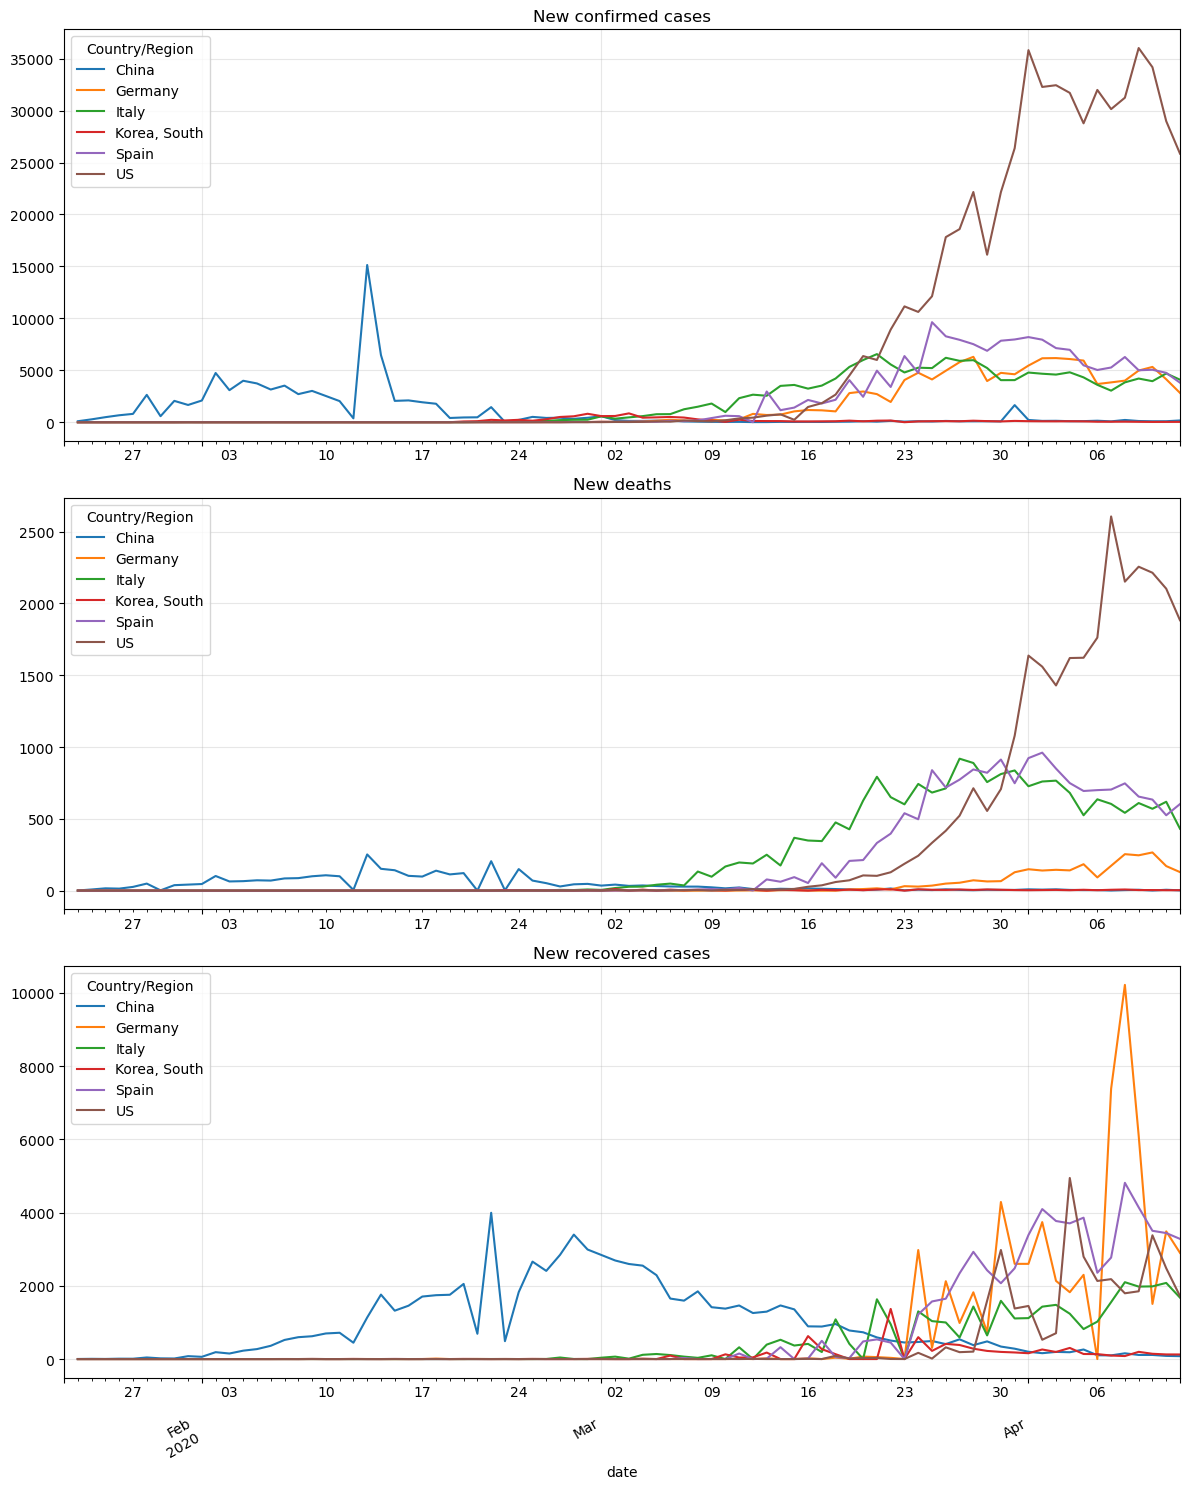

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(12,15))

data = {
    "New confirmed cases": confirmed_history,
    "New deaths": deaths_history,
    "New recovered cases": recovered_history
}

for ax, (title, df) in zip(axes, data.items()):
    df.plot(ax=ax, legend=True)
    ax.set_title(title)
    ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## Prédiction naïve

Prédiction : $\hat{X}_{t+1|t} = X_t$ et par extrapolation : $\forall h \geq 0, \quad \hat{X}_{t+h|t} = X_t$

In [10]:
# Data not seen during training
sub_confirmed_val = confirmed_val[confirmed_val.index >= "2020-04-13"] # Compare predictions with this
naive_pred = predict_naive(confirmed_history)

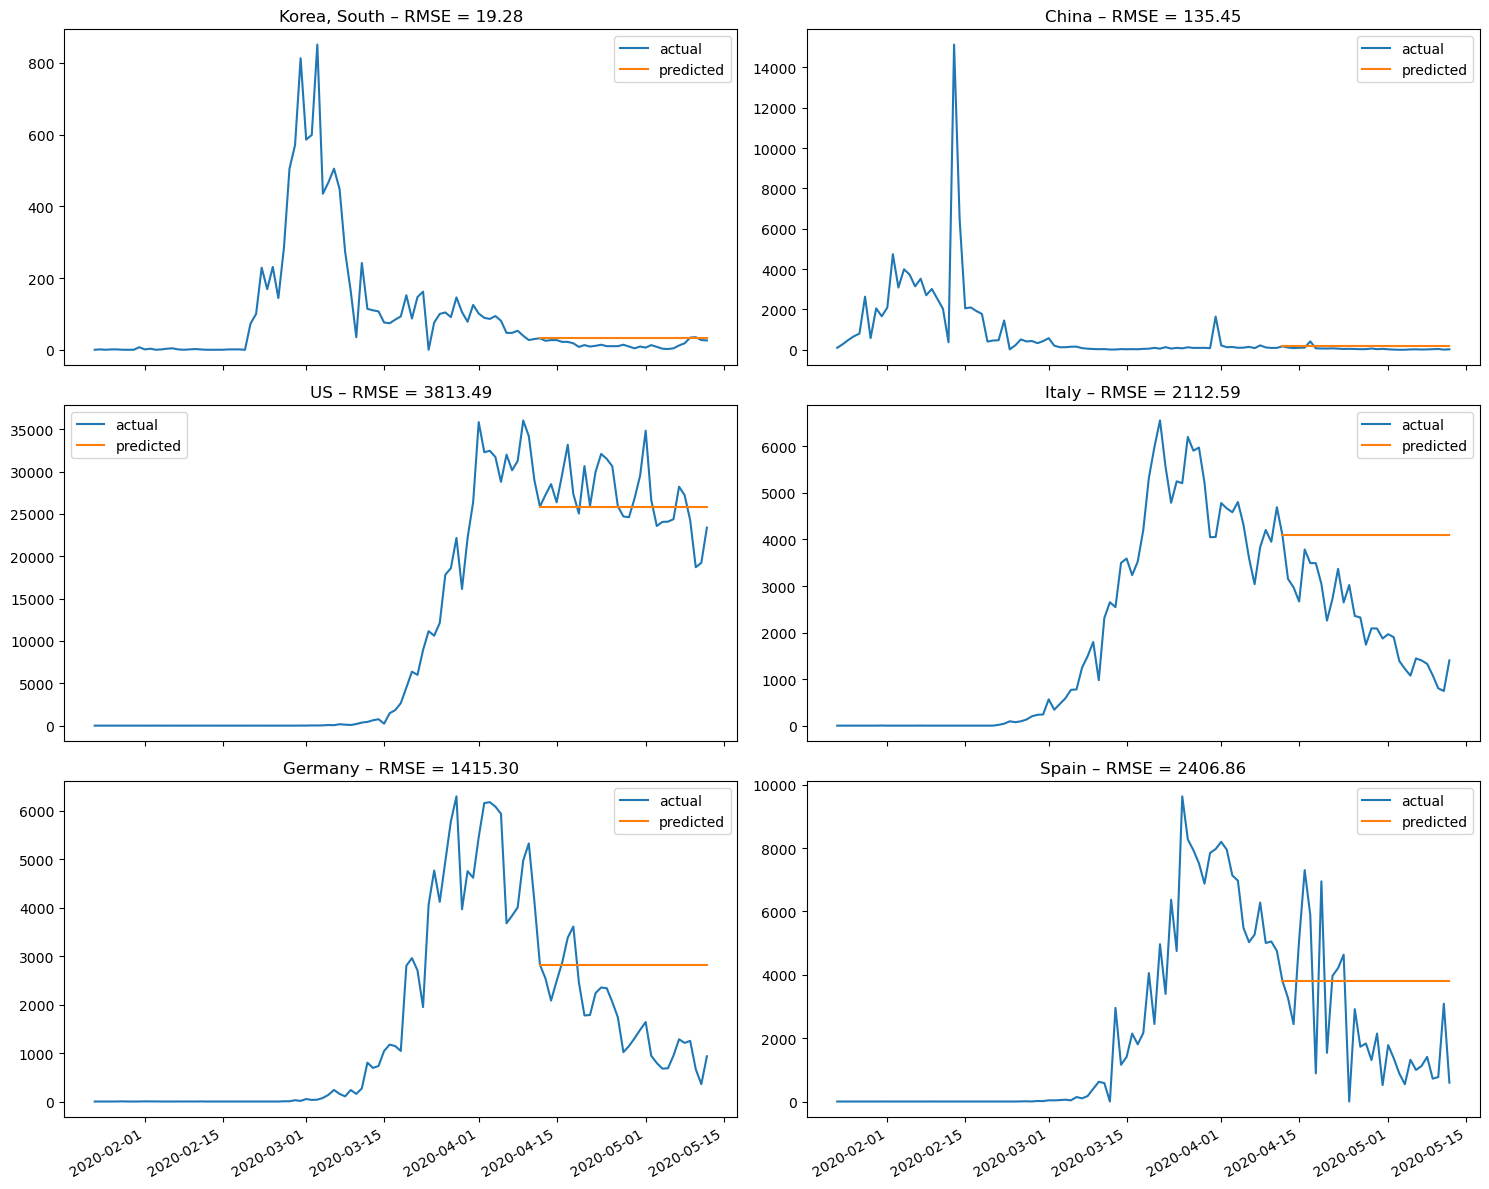

{'Korea, South': 19.28038727135255,
 'China': 135.45417429275975,
 'US': 3813.489513118748,
 'Italy': 2112.5934851109746,
 'Germany': 1415.2971772740875,
 'Spain': 2406.859495968415}

In [11]:
plot_rmse(naive_pred, sub_confirmed_val, confirmed_val)

## Prédiction avec moyenne mobile
Prédiction : $\hat{X}_{t+1|t} = \frac{1}{k} \sum_{j=0}^{k-1}{X_{t-j}}$ et par extension : $\hat{X}_{t+h|t} = \frac{1}{k} \sum_{j=0}^{k-1}{\hat{X}_{t-j}}$ où $\hat{X}_{i} = X_{i}$ si $X_{i}$ est observable.

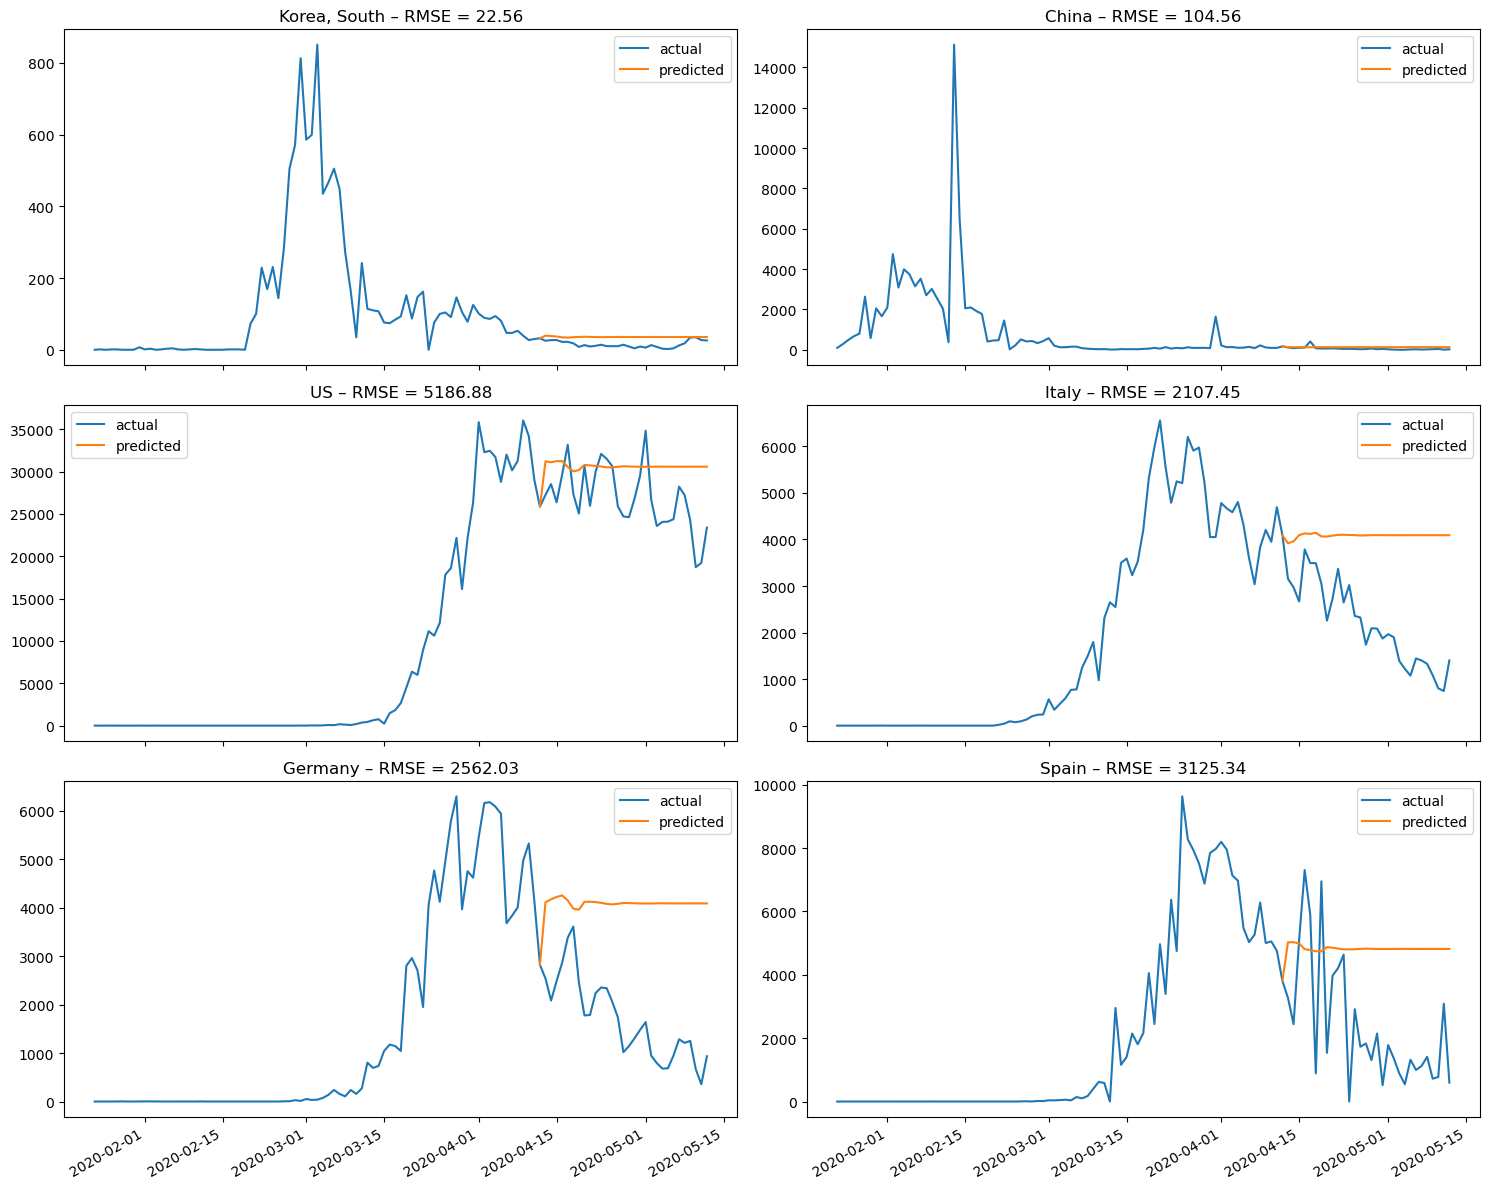

{'Korea, South': 22.556420935468264,
 'China': 104.56141587454906,
 'US': 5186.879878179101,
 'Italy': 2107.454398500752,
 'Germany': 2562.0314331333543,
 'Spain': 3125.34419901419}

In [12]:
pred_ma7 = predict_ma7(history=confirmed_history)
plot_rmse(pred_ma7, sub_confirmed_val, confirmed_val)

In [13]:
print(pred_ma7)

Country/Region       China      Germany        Italy  Korea, South  \
2020-04-12      169.000000  2821.000000  4092.000000     32.000000   
2020-04-13      130.000000  4109.285714  3916.428571     39.285714   
2020-04-14      128.000000  4171.040816  3961.775510     38.183673   
2020-04-15      134.714286  4219.189504  4093.600583     36.924198   
2020-04-16      122.959184  4250.073719  4130.400666     34.627655   
2020-04-17      124.096210  4146.655679  4119.886476     34.003034   
2020-04-18      128.824240  3978.606490  4144.013115     35.003468   
2020-04-19      133.941988  3956.550275  4065.443560     35.718249   
2020-04-20      128.933701  4118.771743  4061.649783     36.249428   
2020-04-21      128.781373  4120.126890  4082.395671     35.815672   
2020-04-22      128.892997  4112.853471  4099.627122     35.477386   
2020-04-23      128.061385  4097.662610  4100.488056     35.270699   
2020-04-24      128.790271  4075.889594  4096.214826     35.362562   
2020-04-25      129.

## Prédiction avec ARIMA(p,d,q) sur chaque série

Pour un pays et une variable donnée, on suit l'approche Box-Jenkins pour identifier l'ordre et les coefficients du modèle :
1. **Sationnarité** : on utilise **ADF** (qui teste si le processus possède une racine unitaire) et **KPSS** (qui teste si le processus est stationnaire autour d'une tendeance déterministe) au seuil de $5%$. On dérive la série tant que $p_{\text{ADF}} \geq 0.05$ ou $p_{\text{KPSS}} < 0.05$.
2. **Identification** : après d différenciations, une ACF et un PACF nous permettent d'identifier les ordres p et q candidats.
3. **Sélection** : le but étant de garder un modèle simple en raison du faible nombre de données, on calcule l'AIC et le BIC  pour tous les ordres candidats et on retient le modèle dont les AIC et BIC forment un "coude".
4. **Diagnostics** : une fois le modèle choisi, on vérifie que ses résidus ressemblent plus ou moin à un bruit blanc (pas d'autocorrélation, normalité, etc.)
5. **Prédiction** : après vérification, on prédit récursivement les prochaines valeurs de la série sur 30 jours

<Axes: xlabel='date'>

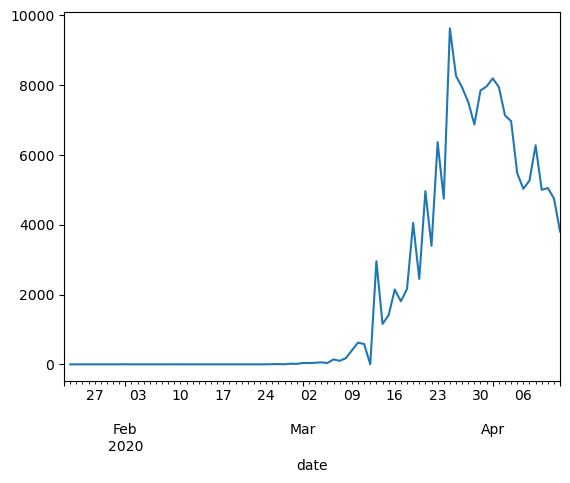

In [14]:
country = "Spain"
series = confirmed_history[country]
series.plot()

### Stationnarité

In [15]:
import warnings
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import ConvergenceWarning,EstimationWarning, InterpolationWarning
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss

Les modèles ARIMA permettent d'étendre les modèles ARMA à des séries qui ne sont pas stationnaires. On va donc commencer par stationnariser la série d'intérêt avant de fit un modèle ARMA sur celle-ci.

In [16]:
def test_stationarity(x):
    x = x.dropna()

    adf_pvalue = adfuller(x,result_object=False)[1] # result_object=False pour ne pas avoir les liens dans les outputs
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        kpss_pvalue = kpss(x, regression="c",result_object=False)[1]

    return adf_pvalue, kpss_pvalue

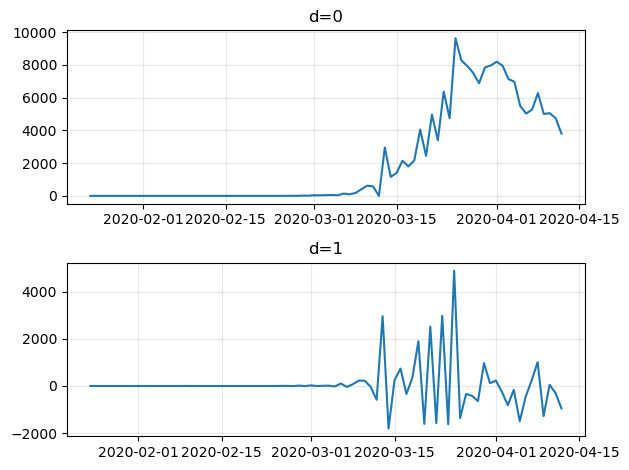

In [17]:
x_diff = series.copy()
results = []
p_adf = 1
p_kpss = 0
d=0

while p_adf>=0.05 or p_kpss < 0.05:
    x=x_diff
    ax=plt.subplot(211+d)
    ax.plot(x.index, x)
    ax.set_title(f"d={d}")
    ax.grid(alpha=0.3)
    p_adf = test_stationarity(x)[0]
    p_kpss = test_stationarity(x)[1]
    results.append({"d": d, "p_adf": p_adf, "p_kpss": p_kpss})
    d=d+1
    x_diff = x.diff().dropna() #attention, si on avait laissé x=x.diff() on aurait eu x différencié d+1 fois compromettant l'identification des ordres. 
else:
    d=d-1

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [18]:
result_table = pd.DataFrame(results).set_index("d")
display(result_table)

,p_adf,p_kpss
d,,
0,7.771420e-01,0.01
1,1.672001e-29,0.10


La boucle précédente différencie x à l'ordre 1. En effet, les tests d'ADF et de KPSS indiquent que la série différenciée une fois est stationnaire. 
On peut maintenant passer à l'étape d'identification du modèle : on trace les graphiques des ACF et PACF qui nous permettront de trouver les ordres p et q des processus AR et MA générant la série temporelle. Plus précisément : 
L'ordre du modèle AR : à partir de quand est-ce que la PACF s'annule
L'ordre du modèle MA : à partir de quand est-ce que l'ACF s'annule 

### Identification

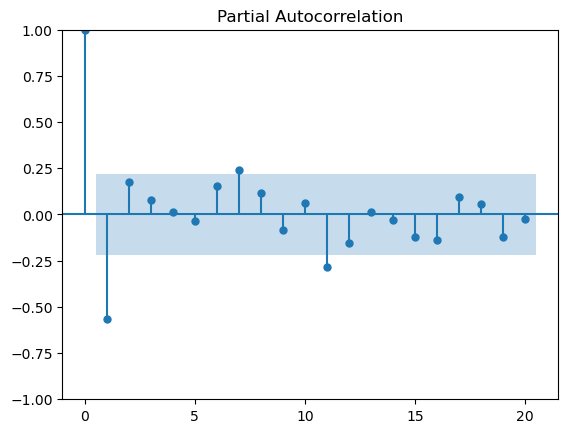

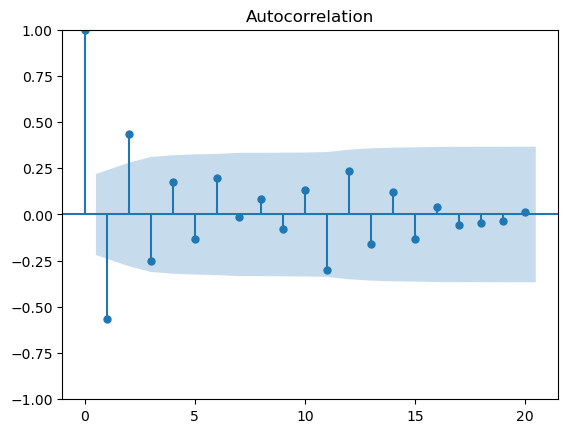

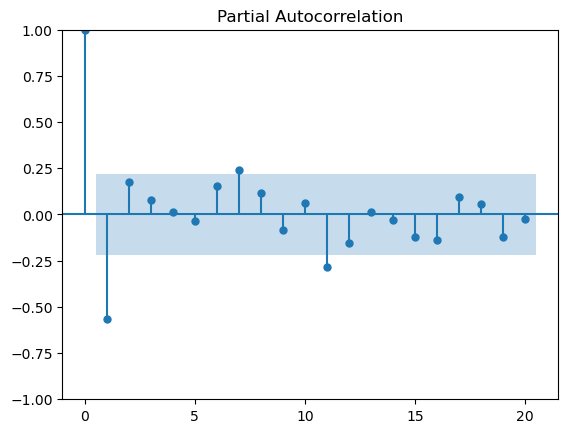

In [19]:
plot_acf(x)
plot_pacf(x)

D'après les graphes précédents, on a un AR d'ordre max 2 et un MA d'ordre max 3. On va maintenant sélectionner les modèles candidats en minimisant l'AIC et le BIC pour ces modèles. On en profite pour regarder l'absence de corrélation des résidus pour les modèles candidats pour savoir si ces derniers sont bien adaptés à notre série.


In [20]:
series = series.asfreq("D")
for p in range(3):
    for q in range (4):
        ARIMA_model =ARIMA(series,order=(p,1,q),freq="D")
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            warnings.simplefilter("ignore", EstimationWarning)
            resultats = ARIMA_model.fit() #objet contenant tous les résultats statistiques et retrait des liens relous
        residus = resultats.resid.iloc[resultats.loglikelihood_burn:].dropna()
        test = acorr_ljungbox(residus, lags=[10], model_df=p + q)
        p_value = test.loc[10, "lb_pvalue"]
        print(f"ARIMA({p},1,{q})  AIC = {resultats.aic:.2f}  "f"BIC = {resultats.bic:.2f}  Ljung–Box (lag 10) : p = {p_value:.3g} convergence du modèle = {resultats.mle_retvals['converged']}")

ARIMA(0,1,0)  AIC = 1344.67  BIC = 1347.06  Ljung–Box (lag 10) : p = 5.77e-09 convergence du modèle = True
ARIMA(0,1,1)  AIC = 1328.02  BIC = 1332.81  Ljung–Box (lag 10) : p = 0.00192 convergence du modèle = True
ARIMA(0,1,2)  AIC = 1318.94  BIC = 1326.12  Ljung–Box (lag 10) : p = 0.129 convergence du modèle = True
ARIMA(0,1,3)  AIC = 1317.08  BIC = 1326.66  Ljung–Box (lag 10) : p = 0.461 convergence du modèle = True
ARIMA(1,1,0)  AIC = 1316.15  BIC = 1320.94  Ljung–Box (lag 10) : p = 0.136 convergence du modèle = True
ARIMA(1,1,1)  AIC = 1316.43  BIC = 1323.62  Ljung–Box (lag 10) : p = 0.265 convergence du modèle = True
ARIMA(1,1,2)  AIC = 1316.82  BIC = 1326.40  Ljung–Box (lag 10) : p = 0.351 convergence du modèle = True
ARIMA(1,1,3)  AIC = 1318.80  BIC = 1330.78  Ljung–Box (lag 10) : p = 0.285 convergence du modèle = False
ARIMA(2,1,0)  AIC = 1315.66  BIC = 1322.85  Ljung–Box (lag 10) : p = 0.353 convergence du modèle = True
ARIMA(2,1,1)  AIC = 1315.98  BIC = 1325.56  Ljung–Box (lag

La minimisation des critères AIC et BIC nous indique de sélectionner le modèle ARIMA(2,1,0). Ce choix est satisfaisant car on ne parvient pas à rejetter l''absence d'autocorrélation des résidus dans le test de Ljung-Box.

In [21]:
ARIMA_model =ARIMA(series,order=(2,1,0),freq="D")  
resultats=ARIMA_model.fit()

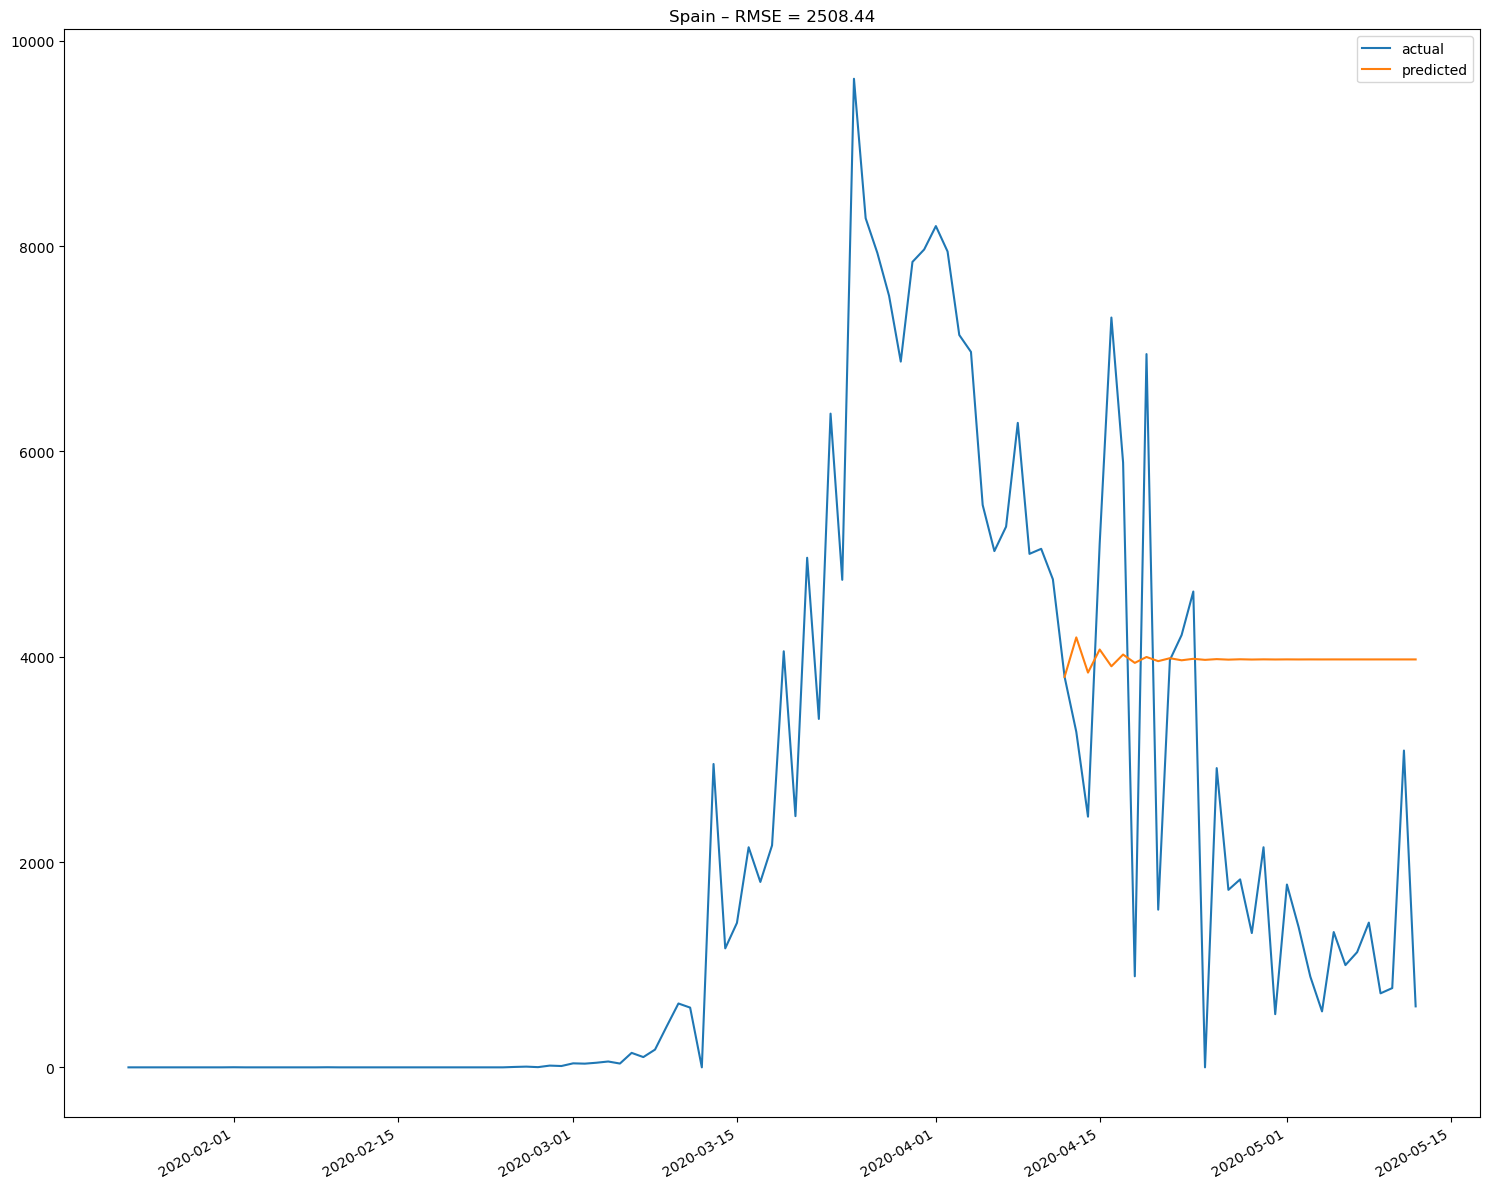

{'Spain': 2508.442466758116}

In [22]:
history = confirmed_history[country]
actual = confirmed_val[country]
forecast = resultats.get_forecast(steps=h)

predictions_plot = pd.concat([history.iloc[-1:], forecast.predicted_mean])

plot_rmse(pred=predictions_plot.to_frame(name=country),true=actual.reindex(forecast.predicted_mean.index).to_frame(name=country),true_long=actual.to_frame(name=country),countries=[country])

Bilan : On voit que le modèle ARIMA améliore encore le forecast, on a la meilleure MSE jusqu'à présent. Mais la RMSE reste importante et les forecasts ne sont pas satisfaisants. 

## Prédiction avec VAR sur $X_t$

Pour un pays donné, on considère :

$$
X_t =
\begin{pmatrix}
\text{confirmed}_t \\
\text{deaths}_t \\
\text{recovered}_t
\end{pmatrix}
$$

On estime :

$$
\Delta X_t = c + \sum_{j=1}^{p} A_j \Delta X_{t-j} + \varepsilon_t
$$

Ce modèle est pertinent parce qu'il existe des liens épidémiologiques naturels entre ces variables :
- Les nouveaux décès dépendent en partie des contaminations antérieures.
- Les guérisons dépendent également des contaminations passées.
- Les trois séries reflètent différentes étapes d'une même dynamique épidémique.

Une autre idée serait d'exploiter les relations entre les dynamiques épidémiques nationales. Mais :
- Les épidémies ne démarrent pas au même moment selon les pays.
- Les dynamiques dépendent de politiques sanitaires, de pratiques de dépistage et de populations très différentes.
- Les relations temporelles entre pays ne sont pas nécessairement stables.
- Le nombre de paramètres devient important pour environ 80 observations.

Méthode d'estimation : On commence par tester la stationnarité des vecteurs grâce aux tests d'ADF et de la racine unitaire comme pour le modèle ARIMA. Ensuite, on va tester l'existence d'une relation de cointégration grâce au test de Johansen. Enfin on pourra estimer un VECM pour $( \text{confirmed}_t,\text{deaths}_t,\text{recovered}_t)$.

### Étapes de l'estimation du modèle :

La première chose que nous devons vérifier est la stationnarité des variables, puis, on déterminera si le système est cointégré avec un tes de johansen. Ensuite le choix des retards se fera grâce à la minimisation du critère AIC. On finira par un test de portmanteau pour vérifier que les résidus ne sont pas autocorrélés.  

### préparation et visualisation des données

<Axes: xlabel='date'>

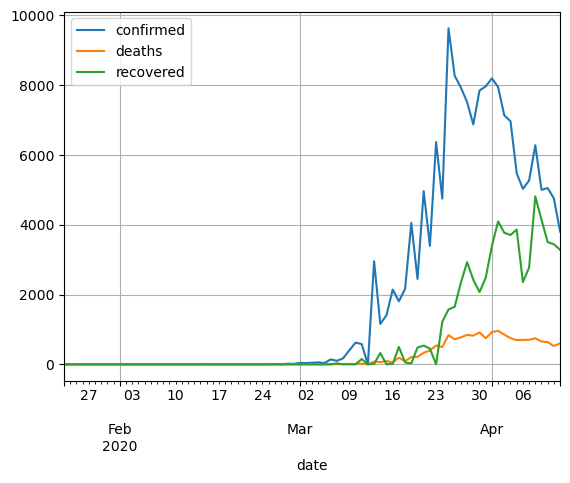

In [ ]:
X=pd.concat([confirmed_history[country].rename("confirmed"),deaths_history[country].rename("deaths"),recovered_history[country].rename("recovered")],axis=1).dropna()
Original_data = X.copy()
X.plot(grid=True) 

On teste la pertinence du modèle vectoriel par le plot de la corrélation à entre les variables à un lag de 0,1,2,3.

In [24]:
!pip install seaborn

In [ ]:
import numpy as np
import seaborn as sns
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import select_coint_rank, select_order

In [ ]:
def correlation_lag(X):
    corr=np.eye(len(X.columns))
    corr = pd.DataFrame(corr, index=X.columns, columns=X.columns)
    fig, ax = plt.subplots(nrows=4, ncols=1, figsize=(10, 10))
    for i in range(4):
        for names in corr.columns:
            for others in corr.columns: 
                    corr.loc[names, others]=X[names].corr(X[others].shift(i))
        sns.heatmap(corr, annot=True, ax=ax[i])
        ax[i].set_title(f"lag{i}")
    fig.tight_layout(h_pad=2.0)

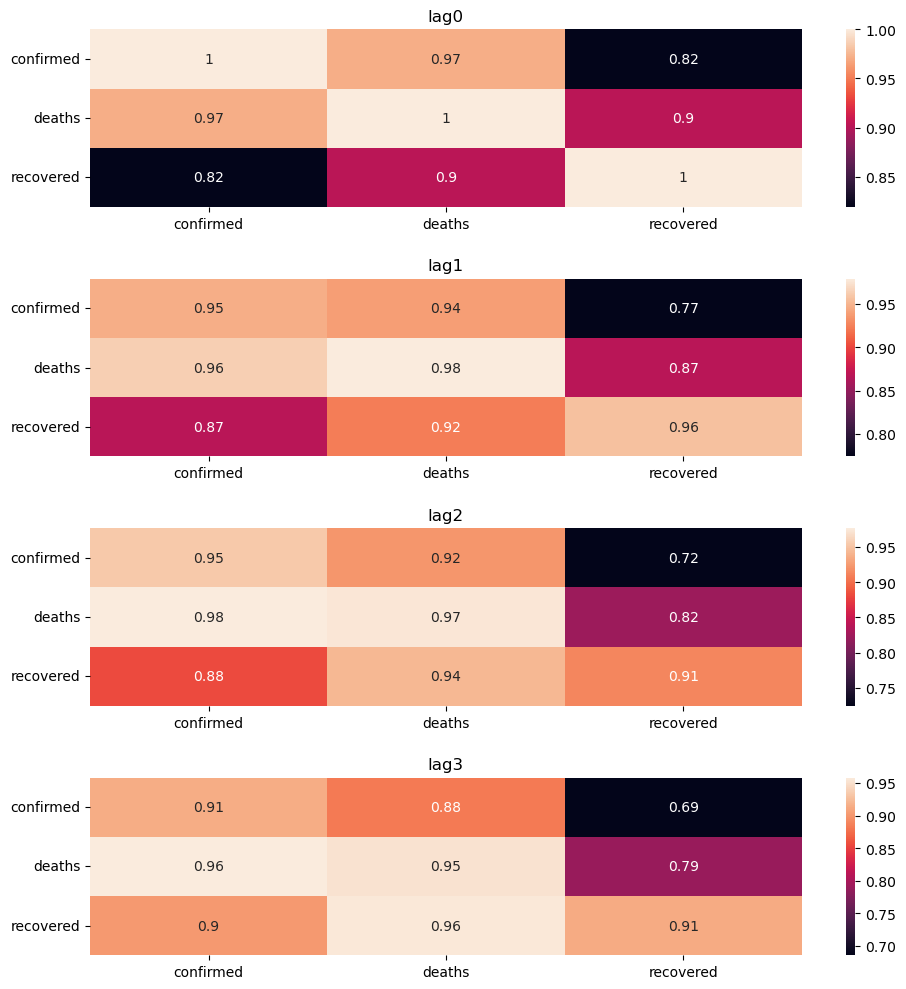

In [26]:
correlation_lag(X)

l'analyse de cette matrice de corrélation nous donne une première idée du lage que l'on va pouvoir utiliser pour notre modèle. Ici on s'intéresse surtout aux corrélations etre une variable explicatives et les autres (l'autocorrelation n'est pas la métrique principale car on cherche à expliquer une information conjointe).
Les matrices de corrélation semblent indiquer qu'un lag de 1 ou de 2 soit optimal. 

### Modèle VAR
Pour fit notre modèle VAR, on commence par stationnariser les entrées du vecteur $X_t$

In [ ]:
def station_0(x):
    S=pd.DataFrame(index=x.index)
    for name in x.columns:
        serie_diff = x[name].dropna().copy()
        p_adf = 1
        p_kpss = 0
        while p_adf >= 0.05 or p_kpss < 0.05:
            serie = serie_diff
            p_adf = test_stationarity(serie)[0]
            p_kpss = test_stationarity(serie)[1]
            serie_diff = serie.diff().dropna() #attention, si on avait laissé x=x.diff() on aurait eu x différencié d+1 fois compromettant l'identification des ordres. 
        else:
            S[name]=serie
            p_adf = 1
            p_kpss = 0

        
    return S.dropna()

X_stat = station_0(Original_data)

La prochaine étape consiste à sélectionner le lag du modèle VAR en minimisant les critèes AIC et BIC. on va chercher un lag "coude" et on va privilégier les petits lags (inférieurs à 3).


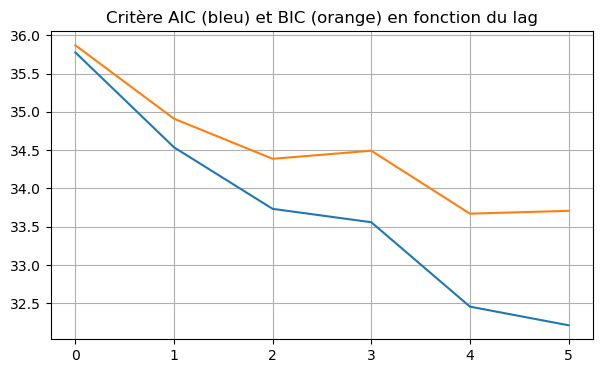

In [ ]:
model_VAR = VAR(X_stat,freq="D")
lags=model_VAR.select_order(maxlags=5)
aic = lags.ics["aic"]
bic = lags.ics["bic"]
ordres = range(len(aic))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ordres, aic)
ax.plot(ordres, bic)
ax.grid()
ax.set_title("Critère AIC (bleu) et BIC (orange) en fonction du lag")
plt.show()

On choisit donc un lag de deux pour obtenir un modèle parcimonieux ce qui est cohérent avec les matrices de correlation que l'on a obtenir dans la partie préliminaire. 
Il nous reste à calibrer un modèle vectoriel et à tester l'autocorrlation des résidus. 

In [29]:
resultats_VAR=model_VAR.fit(2)
test_VAR = resultats_VAR.test_whiteness()
print("Is the model stable? : ",resultats_VAR.is_stable())
print(f"résultats pour un lag de 2")
print(test_VAR.summary())

Is the model stable? :  True
résultats pour un lag de 2
Portmanteau-test for residual autocorrelation. H_0: residual autocorrelation up to lag 10 is zero. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
         182.1          92.81   0.000 72
----------------------------------------


En revanche, le test de Portmanteau rejette l'absence de corrélation pour le modèle de lag 2. Ainsi le modèle échoue à capturer la dynamique temporelle de la série $X$.
Il n'est donc pas adapté. 

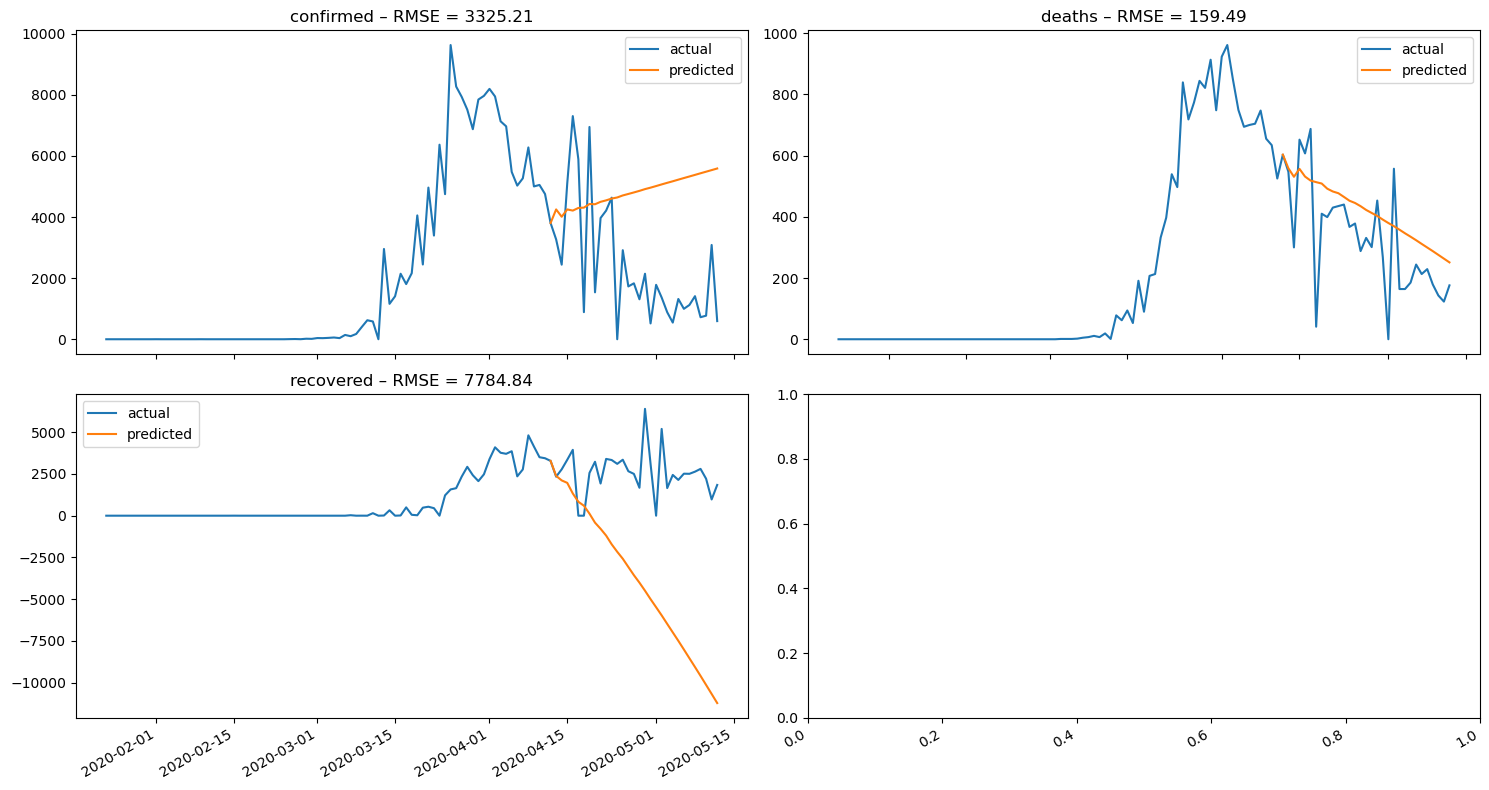

In [ ]:
lag_order = 2
resultats_var = VAR(X_stat,freq="D").fit(lag_order)#je ne crois pas que la trend améliore nécessairement le modèle trend='c'. On peut faire des tests de trend cf projet ENSAE.

forecast_input = X_stat.values[-lag_order:]
fc = resultats_var.forecast(y=forecast_input, steps=h)
df_forecast = pd.DataFrame(fc,index=pd.date_range(Original_data.index[-1] + pd.Timedelta(days=1),periods=h,freq="D"),columns=Original_data.columns)

def invert_transformation(df_train, df_forecast, orders):
    df_fc = df_forecast.copy()
    for col, d in orders.items():
        y = df_fc[col]
        if d == 2:
            y = df_train[col].diff().iloc[-1] + y.cumsum()
        if d >= 1:
            y = df_train[col].iloc[-1] + y.cumsum()
        df_fc[col + '_forecast'] = y
    return df_fc

orders = {'confirmed': 1, 'deaths': 2, 'recovered': 2} # dans cette partie, on réintègre les séries que l'on avait différenciées pour obtenir un système stationnaire
df_results = invert_transformation(Original_data, df_forecast, orders)
actual = pd.DataFrame({"confirmed": confirmed_val[country],"deaths": deaths_val[country],"recovered": recovered_val[country]})

colonnes = Original_data.columns.tolist()

# Récupérer les prévisions reconstruites avec les mêmes noms que les observations.
prevs = df_results[[f"{col}_forecast" for col in colonnes]].copy()
prevs.columns = colonnes

observations_test = actual.loc[prevs.index, colonnes]
observations_plot = pd.concat([Original_data[colonnes], observations_test])
previsions_plot = pd.concat([Original_data[colonnes].iloc[[-1]], prevs])

rmse_var = plot_rmse(pred=previsions_plot,true=observations_test,true_long=observations_plot,countries=colonnes)

### Modèle VECM :
L'APPORT DU VECM C'EST LA TENDANCE!!! JUSTEMENT LE VAR PRODUIT DES OUTPUTS LINÉAIRES ALORS QUE LE VECM EST CAPABLE DE METTRE UN TERM DE TENDANCE DANS LE MODELE ET DE MODÉLISER DES PHÉNOMÈNES DE RETOUR À LA MOYENNE!!!
DONC C'EST UN AJOUT INTERESSANT!
attention, il faut impérativement revoir ce modèle et comment est ce que l'on peut l'interpréter. Cf cours ST an dernier. 
On commence par tester l'existence d'une racine unitaire pour chacune des séries présentes dans le vecteur X. Notre but est d'obtenir un vecteur dont toutes les composantes sont I(1). Ces relations de coïntégration peuvent permettre de mieux comprendre la dynamique linéaire conjointe des séries de notre modèle.
On va donc différencier nos séries jusqu'à ce que l'on obtienne un vecteur de séries cointégreés. 
Ensuite, le test de Johansen nous permettra de trouver le nombre de relations de cointégration dans le système. 
Dès lors, la minimisation des critères AIC et BIC nous permettrons de déterminer le lag du modèle VECM. 
On testera ensuite l'autocorrélation des résidus et on passera à l'analyse des prédictions du modèle choisi. 

In [40]:
from datetime import date, timedelta

import numpy as np
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import VECM, select_coint_rank, select_order

Cette fonction nous permet d'obtenir le nombre de différentiations nécessaires à chaque série pour qu'elle soit stationnaire. 
Elle va nous permettre d'identifier quelles sériés qu'on doit rendre I(1) pour povoir estimer un modèle VECM.

In [41]:
X = Original_data.copy()

def station_1(x):
    S=pd.DataFrame(index=x.index)
    k=0
    d={}
    for name in x.columns:
        serie_diff = x[name].dropna().copy()
        p_adf = 1
        p_kpss = 0
        d[name]=0
        while p_adf >= 0.05 or p_kpss < 0.05:
            serie = serie_diff
            p_adf = test_stationarity(serie)[0]
            p_kpss = test_stationarity(serie)[1]
            d[name]=d[name]+1
            serie_diff = serie.diff().dropna() 
        else:
            d[name]=d[name]-1
            S[name]=serie
            k+=1
            p_adf = 1
            p_kpss = 0

        
    return S.dropna(),d 

station_1(X)

(            confirmed  deaths  recovered
 date                                    
 2020-01-25        0.0     0.0        0.0
 2020-01-26        0.0     0.0        0.0
 2020-01-27        0.0     0.0        0.0
 2020-01-28        0.0     0.0        0.0
 2020-01-29        0.0     0.0        0.0
 ...               ...     ...        ...
 2020-04-08     1011.0    39.0     1628.0
 2020-04-09    -1276.0  -135.0    -2711.0
 2020-04-10       49.0    71.0       28.0
 2020-04-11     -297.0   -88.0      579.0
 2020-04-12     -950.0   187.0      -97.0
 
 [79 rows x 3 columns],
 {'confirmed': 1, 'deaths': 2, 'recovered': 2})

d'après le test précédent, death et recovered sont I(2), donc pour satisfaire les hypothèses du test de johansen : toutes les séries sont I(1) on différencie ces composantes.


In [42]:
Delta_recovered=X['recovered'].diff()
X['recovered']=Delta_recovered
Delta_recovered=X['deaths'].diff()
X['deaths']=Delta_recovered

La dernière étape avant le test de Johansen est la sélection de l'ordre du modèle par les critères AIC et BIC.
La prochaine étape consiste à sélectionner le lag du modèle VAR en minimisant les critèes AIC et BIC. on va chercher un lag "coude" et on va privilégier les petits lags (inférieurs à 3).

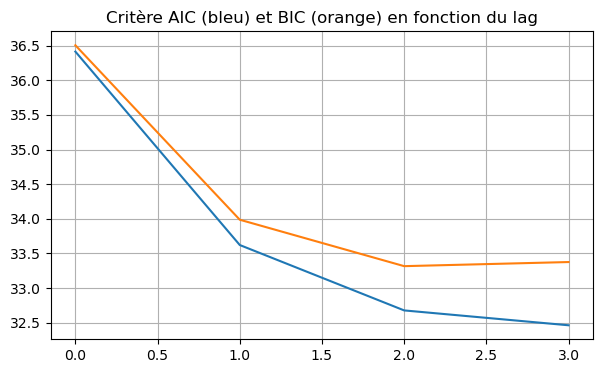

In [43]:
X=X.dropna()
model = VAR(X,freq="D")
lags=model.select_order(maxlags=3)
aic = lags.ics["aic"]
bic = lags.ics["bic"]
ordres = range(len(aic))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ordres, aic)
ax.plot(ordres, bic)
ax.grid()
ax.set_title("Critère AIC (bleu) et BIC (orange) en fonction du lag")
plt.show()

On retient l'ordre 1 et 2 pour les ordres du VECM car c'est là qu'il semble y avoir le coude pour l'AIC et le BIC mais lon ne tranche pas franchement pour un lag en particulier.
Ainsi il ne nous reste que le test de Johansen à effectuer avec les lags 0 et 1  

In [44]:
print(f"Rang retenu pour lag 1")
test_lag2=select_coint_rank(X,det_order=1,k_ar_diff= 1 ,method="trace",signif=0.05)
print(test_lag2.summary())
print("Rang retenu =", test_lag2.rank)

Rang retenu pour lag 1
Johansen cointegration test using trace test statistic with 5% significance level
r_0 r_1 test statistic critical value
-------------------------------------
  0   3          158.3          35.01
  1   3          62.37          18.40
  2   3          2.922          3.841
-------------------------------------
Rang retenu = 2


comme les séries présentent des tendances non linéaires, j'ai envie de tester le modèle avec une tendance quadratiquela linéaire quadratique amliore grandement les prévisions! faudrait qu'on puisse voir quels sont les coefficients et leur significativité stat. Mais pourquoi est ce que la tendance améliore les prévisions dans le VECM mais pas dans un VAR?


In [ ]:
model = VECM(X, k_ar_diff=1, coint_rank=2, deterministic="li",freq="D") 
resultats_vecm = model.fit()
test = resultats_vecm.test_whiteness()
print(test.summary())

Portmanteau-test for residual autocorrelation. H_0: residual autocorrelation up to lag 10 is zero. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
         179.8          96.22   0.000 75
----------------------------------------


là encore, le VECM échoue à capturer toute la dynamique temporelle de la série...

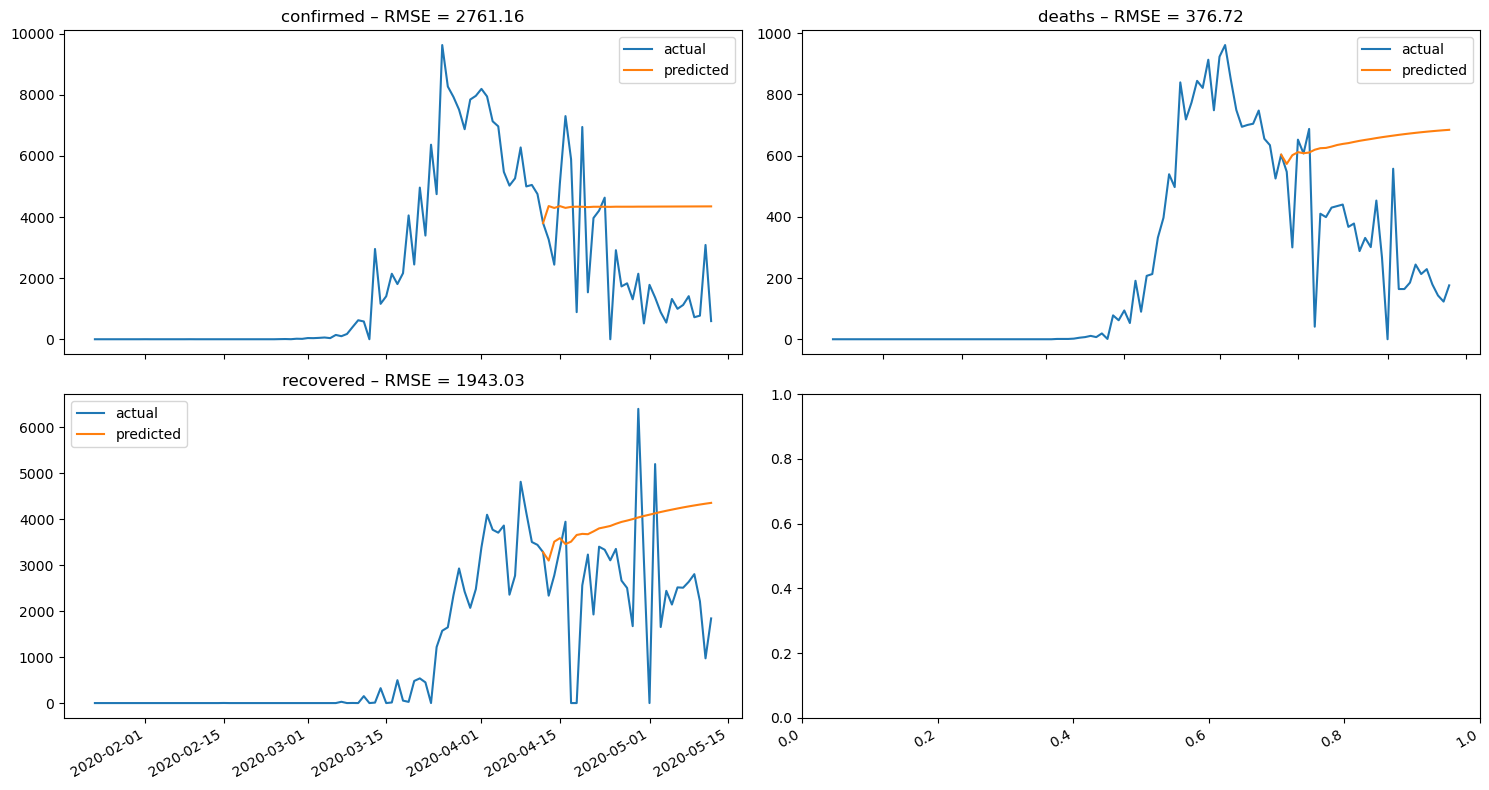

{'confirmed': 2761.163100765653,
 'deaths': 376.7228766573021,
 'recovered': 1943.0305808674677}

In [46]:
def previsions(X):
    actual = pd.concat([confirmed_val[country].rename("confirmed"),deaths_val[country].rename("deaths"),recovered_val[country].rename("recovered"),], axis=1)

    derniere_date = X.index[-1]
    dates_forecast = pd.date_range(start=derniere_date + pd.Timedelta(days=1),periods=h,freq="D")
    Prevs = pd.DataFrame(resultats_vecm.predict(steps=h),index=dates_forecast,columns=X.columns)
    dernier_point = Original_data.loc[[derniere_date], X.columns]

    for name in ["deaths", "recovered"]:
        initial = dernier_point[name].iloc[0]
        Prevs[name] = initial + Prevs[name].cumsum()

    Prevs_plot = pd.concat([dernier_point, Prevs])
    colonnes = X.columns.tolist()
    return plot_rmse(pred=Prevs_plot,true=actual.loc[dates_forecast, colonnes],true_long=actual.loc[:, colonnes],countries=colonnes)

previsions(X)

Le VECM conclut l'étude des modèles linéaires pour capter le développemet de l'épidémie de covid. Cependant on voit que les RMSE restent élevées et graohiquement, on ne capte pas le caractère erratique des séies, on produit une approximation trop lisse (oui trouver une métrique). 
Le problème de l'introduction d'une tendance peut résider dans le fait qu'elle ne nous permettra pas de capter des phénomènes de vagues épidémiques ce qui justifie le passage à l'étude de moèdeles structurels d'épidémiologie et ensuite l'utilisation de la NMF.

# Conclusion : 
Les modèles ARIMA, VAR et VECM à paramètres constants rencontrent des difficultés sur ces données, potentiellement liées à leur forte non-stationnarité, à l'hétéroscédasticité et aux changements de régime. Ces résultats motivent l'évaluation d'approches alternatives, notamment Online NMF.
En ce qui concerne les performances intermodèles, le modèle ayant la RMSE la moins élevé est le modele VECM cependant on n'arrive à observer l'absence d'autocorrlation des résidus avec une statistique pour le test de portmanteau qui est largement au dessus de la valeur critique. 
Les modèles VAR et ARIMA n'améliorent pas leurs performances quand on ajoute une tendace linéaire ou quadratique. 